# Shared low-field optimization experiments

Every run has one parameter set for $L=2,4,6,8$; all four sizes contribute to
every update. These continuations start from checkpoints chosen by the recorded development comparison.
The selected family uses two independent training seeds; a conservative SR branch and a different candidate family provide further comparisons. Initializations and schedules are listed below.
All four continuations use the declared discrete anchor schedule. Exact states are evaluation-only.
The completion ablation adds the independent-spin quantum energy response of
future nearest neighbors to each candidate cell. Its initial gate is inherited from the selected checkpoint;
future/future interactions still have to be learned by the network.

With $O=\partial_\theta\log\psi$, SR uses the equal-context metric
$S=\frac14\sum_c \mathrm{Cov}_c(O,O)/N_c$ and the physical force
$g=\frac14\sum_c2\mathrm{Cov}_c(O,E_{\rm loc})/N_c$.
It solves $(S+\lambda I)d=g$ in sample space, then applies $\theta\leftarrow\theta-\eta d$.
The effective rate limits the largest sampled RMS change in $\log\psi$ to 0.05.
This is a sampled linear trust limit, not an exact bound on the new-state KL.

Development IDs 10000–10007 select these continuations; routine curves use 10000–10001; IDs 40000–40007 remain reserved.
Energy, fidelity, connected susceptibility, and local-energy variance must be
read together: a near-excited eigenstate can have a small variance. Finite-size
spectra distinguish this failure from ordinary broad high-energy contamination.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path('/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_low_field_overnight_v1')
runs={}
for path in sorted(ROOT.glob('*/campaign.json')):
    if path.parent.name.startswith('benchmark'): continue
    manifest=json.loads(path.read_text())
    history=json.loads((path.parent/'history.json').read_text()) if (path.parent/'history.json').exists() else []
    status=json.loads((path.parent/'status.json').read_text()) if (path.parent/'status.json').exists() else {}
    validations=[dict(json.loads(p.read_text()), step=int(p.stem.split('_')[-1])) for p in sorted(path.parent.glob('validation_*.json'))]
    runs[path.parent.name]=dict(manifest=manifest,history=history,status=status,validations=validations)
assert runs, 'No executed experiments found'
identities={r['manifest']['initialization_sha256'] for r in runs.values()}
if not True:
    assert len(identities)==1, 'Controlled comparison requires identical initialization'
    display(Markdown('**Shared initialization SHA-256:** `'+next(iter(identities))+'`'))
else:
    decision=json.loads((ROOT/'selection.json').read_text())
    display(Markdown('**Development selection score:** '+decision['policy']['selection']))
    ranking=['| Candidate | Score | Low-field infidelity | C RMS error | Absolute χ error | High-field retained |','|---|---:|---:|---:|---:|---|']
    for candidate in decision['ranked']:
        ranking.append(f"| {Path(candidate['checkpoint']).parent.name} / {Path(candidate['checkpoint']).name} | {candidate['score']:.6f} | {candidate['mean_low_field_infidelity']:.6f} | {candidate['mean_low_field_C_rms']:.6f} | {candidate['mean_low_field_absolute_chi_error']:.6f} | {candidate['high_field_retained']} |")
    display(Markdown('\n'.join(ranking)))
    final_selection=ROOT/'final_selection.json'
    if final_selection.exists():
        final_decision=json.loads(final_selection.read_text())
        assert not final_decision['reserved_tests_inspected']
        ranking=['| Candidate | Phase | Final development score | Minimum high-field fidelity |','|---|---|---:|---:|']
        for candidate in final_decision['ranked']:
            ranking.append(f"| {Path(candidate['checkpoint']).parent.name} / {Path(candidate['checkpoint']).name} | {candidate['phase']} | {candidate['score']:.6f} | {candidate['lowest_high_field_fidelity']:.6f} |")
        display(Markdown('**Completed continuation selection**\n\n'+'\n'.join(ranking)))
        display(Markdown(final_decision['candidate_scope']+' '+final_decision['interpretation']))
    table=['| Run | Method | Continuous fields | Completion | Initialization SHA-256 |', '|---|---|---|---|---|']
    for name,r in runs.items():
        m=r['manifest']
        table.append(f"| {name} | {m['method']} | {m['continuous']} | {m['architecture'].get('completion',False)} | `{m['initialization_sha256']}` |")
    display(Markdown('\n'.join(table)))
table=['| Run | Status | Updates | Low/high batch | Peak tensor GB | Training seconds |', '|---|---|---:|---:|---:|---:|']
for name,r in runs.items():
    hist=r['history']; m=r['manifest']
    table.append(f"| {name} | {r['status'].get('state','starting')} | {hist[-1]['step'] if hist else 0} / {m['steps']} | {m['batch']} / {m['high_batch']} | {max([v['peak_gpu_bytes'] for v in hist],default=0)/1e9:.2f} | {hist[-1]['seconds'] if hist else 0:.1f} |")
display(Markdown('\n'.join(table)))
for name,r in runs.items():
    verification=ROOT/name/'transfer_verification.json'
    if verification.exists():
        identity=json.loads(verification.read_text())
        checkpoint=ROOT/name/identity['checkpoint']
        assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==identity['sha256']
        display(Markdown('**'+name+' verified final checkpoint:** `'+identity['sha256']+'`'))


**Development selection score:** mean low-field infidelity + 0.25 mean off-diagonal connected-C RMS + 0.02 mean absolute connected susceptibility error; lowest high-field fidelity >=0.98 preferred

| Candidate | Score | Low-field infidelity | C RMS error | Absolute χ error | High-field retained |
|---|---:|---:|---:|---:|---|
| results / shared_symmetric_alibi__L02-04-06-08__seed501__final.pt | 0.291550 | 0.238681 | 0.159029 | 0.655594 | True |
| adam601 / shared_adam_replay0__L02-04-06-08__seed601__final.pt | 0.321078 | 0.266607 | 0.165686 | 0.652460 | True |
| sr_completion601 / shared_sr_replay0__completion1__L02-04-06-08__seed601__final.pt | 0.337052 | 0.279657 | 0.170441 | 0.739269 | True |
| sr602 / shared_sr_replay0__L02-04-06-08__seed602__final.pt | 0.351644 | 0.294720 | 0.168632 | 0.738290 | True |
| sr601 / shared_sr_replay0__L02-04-06-08__seed601__final.pt | 0.361593 | 0.306302 | 0.165755 | 0.692641 | True |
| sr_replay601 / shared_sr_replay1__L02-04-06-08__seed601__final.pt | 0.363593 | 0.305945 | 0.169800 | 0.759913 | True |
| results / shared_symmetric_alibi__step003600.pt | 0.372679 | 0.316949 | 0.168648 | 0.678398 | True |

**Completed continuation selection**

| Candidate | Phase | Final development score | Minimum high-field fidelity |
|---|---|---:|---:|
| results / shared_symmetric_alibi__L02-04-06-08__seed501__final.pt | predecessor | 0.291550 | 0.991539 |
| selected702 / shared_adam_replay0__L02-04-06-08__seed702__final.pt | overnight_final | 0.304952 | 0.991666 |
| selected701 / shared_adam_replay0__L02-04-06-08__seed701__final.pt | overnight_final | 0.309836 | 0.991311 |
| adam601 / shared_adam_replay0__L02-04-06-08__seed601__final.pt | predecessor | 0.321078 | 0.990981 |
| sr_completion601 / shared_sr_replay0__completion1__L02-04-06-08__seed601__final.pt | predecessor | 0.337052 | 0.991668 |
| sr602 / shared_sr_replay0__L02-04-06-08__seed602__final.pt | predecessor | 0.351644 | 0.991027 |
| alternative704 / shared_sr_replay0__completion1__L02-04-06-08__seed704__final.pt | overnight_final | 0.352575 | 0.992639 |
| sr601 / shared_sr_replay0__L02-04-06-08__seed601__final.pt | predecessor | 0.361593 | 0.991173 |
| conservative_sr703 / shared_sr_replay0__L02-04-06-08__seed703__final.pt | overnight_final | 0.363295 | 0.991109 |
| sr_replay601 / shared_sr_replay1__L02-04-06-08__seed601__final.pt | predecessor | 0.363593 | 0.989983 |
| results / shared_symmetric_alibi__step003600.pt | predecessor | 0.372679 | 0.989263 |

Seven predecessor candidates and four overnight final checkpoints. Intermediate snapshots not ranked. Development selection only; no larger-size accuracy certification.

| Run | Method | Continuous fields | Completion | Initialization SHA-256 |
|---|---|---|---|---|
| alternative704 | sr | False | True | `022d9bf942b325b7d730eea73b78c336d1944e2231ba26dcbfe3606a0c7af300` |
| conservative_sr703 | sr | False | False | `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544` |
| selected701 | adam | False | False | `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544` |
| selected702 | adam | False | False | `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544` |

| Run | Status | Updates | Low/high batch | Peak tensor GB | Training seconds |
|---|---|---:|---:|---:|---:|
| alternative704 | completed | 1800 / 1800 | 1024 / 512 | 14.17 | 13851.4 |
| conservative_sr703 | completed | 1800 / 1800 | 1024 / 512 | 28.27 | 13593.8 |
| selected701 | completed | 1800 / 1800 | 1024 / 512 | 1.81 | 11655.3 |
| selected702 | completed | 1800 / 1800 | 1024 / 512 | 1.81 | 11674.3 |

**alternative704 verified final checkpoint:** `4149548e74e4ab62bf69ccb1629be0a9a026e95a4cca3396410c6e0ccc4228d1`

**conservative_sr703 verified final checkpoint:** `ff110ae0acffeadf1772caf784223f143484a1e48dc435aaf7b3e8177093ae17`

**selected701 verified final checkpoint:** `7e87b53a3b403f7ddc510cd26d49c1af451d133ebcc515e2803caad17bbc5628`

**selected702 verified final checkpoint:** `73665d1065a44373acaf7df754f11c8bc7c3044d2c66b2bbbb0e004d0af040c5`

In [2]:
table=['| Run | Γ | h | Validation error/spin | Fidelity | Lowest fidelity | Mean absolute χ error | Variance/spin |', '|---|---:|---:|---:|---:|---:|---:|---:|']
for name,r in runs.items():
    if not r['validations']: continue
    rows=r['validations'][-1]['rows']
    for gamma,h in ((.5,0.),(.5,.3),(2.,.3)):
        selected=[v for v in rows if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
        if not selected: continue
        table.append(f"| {name} | {gamma} | {h} | {np.mean([v['energy_error_per_spin'] for v in selected]):.6f} | {np.mean([v['fidelity'] for v in selected]):.5f} | {min(v['fidelity'] for v in selected):.5f} | {np.mean([abs(v['chi_connected']-v['exact_chi']) for v in selected]):.5f} | {np.mean([v['variance_per_spin'] for v in selected]):.6f} |")
display(Markdown('\n'.join(table)))


| Run | Γ | h | Validation error/spin | Fidelity | Lowest fidelity | Mean absolute χ error | Variance/spin |
|---|---:|---:|---:|---:|---:|---:|---:|
| alternative704 | 0.5 | 0.0 | 0.010241 | 0.88387 | 0.82460 | 0.26020 | 0.025091 |
| alternative704 | 0.5 | 0.3 | 0.022692 | 0.55441 | 0.34801 | 0.54425 | 0.031891 |
| alternative704 | 2.0 | 0.3 | 0.000941 | 0.99832 | 0.99817 | 0.00715 | 0.008301 |
| conservative_sr703 | 0.5 | 0.0 | 0.010380 | 0.89739 | 0.85870 | 0.33326 | 0.025493 |
| conservative_sr703 | 0.5 | 0.3 | 0.025149 | 0.50086 | 0.33318 | 0.49451 | 0.034143 |
| conservative_sr703 | 2.0 | 0.3 | 0.001332 | 0.99766 | 0.99732 | 0.00686 | 0.011573 |
| selected701 | 0.5 | 0.0 | 0.010937 | 0.90919 | 0.85443 | 0.02780 | 0.033827 |
| selected701 | 0.5 | 0.3 | 0.027265 | 0.51729 | 0.44227 | 0.64618 | 0.046546 |
| selected701 | 2.0 | 0.3 | 0.001348 | 0.99774 | 0.99729 | 0.00867 | 0.011968 |
| selected702 | 0.5 | 0.0 | 0.010924 | 0.89761 | 0.84459 | 0.22770 | 0.033702 |
| selected702 | 0.5 | 0.3 | 0.024152 | 0.54244 | 0.49340 | 0.64449 | 0.042877 |
| selected702 | 2.0 | 0.3 | 0.001356 | 0.99770 | 0.99724 | 0.00728 | 0.012123 |

In [3]:
table=['| Run | Latest validation | Γ | h | Mean fidelity | Change from step 0 | Mean error/spin | Mean absolute χ error |','|---|---:|---:|---:|---:|---:|---:|---:|']
for name,r in runs.items():
    if not r['validations']: continue
    latest=max(r['validations'],key=lambda v:v['step'])
    initial=next((v for v in r['validations'] if v['step']==0),None)
    if initial is None: continue
    for gamma,h in ((.5,0.),(.5,.3),(2.,.3)):
        current=[v for v in latest['rows'] if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
        start=[v for v in initial['rows'] if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
        if not current or not start: continue
        fidelity=np.mean([v['fidelity'] for v in current])
        start_fidelity=np.mean([v['fidelity'] for v in start])
        table.append(f"| {name} | {latest['step']} | {gamma} | {h} | {fidelity:.5f} | {fidelity-start_fidelity:+.5f} | {np.mean([v['energy_error_per_spin'] for v in current]):.6f} | {np.mean([abs(v['chi_connected']-v['exact_chi']) for v in current]):.5f} |")
display(Markdown('**Latest measured change from each run relative to its step-0 validation**\n\n'+'\n'.join(table)))


**Latest measured change from each run relative to its step-0 validation**

| Run | Latest validation | Γ | h | Mean fidelity | Change from step 0 | Mean error/spin | Mean absolute χ error |
|---|---:|---:|---:|---:|---:|---:|---:|
| alternative704 | 1800 | 0.5 | 0.0 | 0.88387 | -0.02101 | 0.010241 | 0.26020 |
| alternative704 | 1800 | 0.5 | 0.3 | 0.55441 | -0.02647 | 0.022692 | 0.54425 |
| alternative704 | 1800 | 2.0 | 0.3 | 0.99832 | +0.00036 | 0.000941 | 0.00715 |
| conservative_sr703 | 1800 | 0.5 | 0.0 | 0.89739 | -0.03559 | 0.010380 | 0.33326 |
| conservative_sr703 | 1800 | 0.5 | 0.3 | 0.50086 | -0.11306 | 0.025149 | 0.49451 |
| conservative_sr703 | 1800 | 2.0 | 0.3 | 0.99766 | +0.00070 | 0.001332 | 0.00686 |
| selected701 | 1800 | 0.5 | 0.0 | 0.90919 | -0.02379 | 0.010937 | 0.02780 |
| selected701 | 1800 | 0.5 | 0.3 | 0.51729 | -0.09663 | 0.027265 | 0.64618 |
| selected701 | 1800 | 2.0 | 0.3 | 0.99774 | +0.00078 | 0.001348 | 0.00867 |
| selected702 | 1800 | 0.5 | 0.0 | 0.89761 | -0.03537 | 0.010924 | 0.22770 |
| selected702 | 1800 | 0.5 | 0.3 | 0.54244 | -0.07148 | 0.024152 | 0.64449 |
| selected702 | 1800 | 2.0 | 0.3 | 0.99770 | +0.00074 | 0.001356 | 0.00728 |

**Largest validation update shared by every run**

| Run | Matched updates | Γ | h | Mean error/spin | Mean fidelity | Change in fidelity | Mean absolute χ error |
|---|---:|---:|---:|---:|---:|---:|---:|
| alternative704 | 1800 | 0.5 | 0.0 | 0.010241 | 0.88387 | -0.02101 | 0.26020 |
| alternative704 | 1800 | 0.5 | 0.3 | 0.022692 | 0.55441 | -0.02647 | 0.54425 |
| alternative704 | 1800 | 2.0 | 0.3 | 0.000941 | 0.99832 | +0.00036 | 0.00715 |
| conservative_sr703 | 1800 | 0.5 | 0.0 | 0.010380 | 0.89739 | -0.03559 | 0.33326 |
| conservative_sr703 | 1800 | 0.5 | 0.3 | 0.025149 | 0.50086 | -0.11306 | 0.49451 |
| conservative_sr703 | 1800 | 2.0 | 0.3 | 0.001332 | 0.99766 | +0.00070 | 0.00686 |
| selected701 | 1800 | 0.5 | 0.0 | 0.010937 | 0.90919 | -0.02379 | 0.02780 |
| selected701 | 1800 | 0.5 | 0.3 | 0.027265 | 0.51729 | -0.09663 | 0.64618 |
| selected701 | 1800 | 2.0 | 0.3 | 0.001348 | 0.99774 | +0.00078 | 0.00867 |
| selected702 | 1800 | 0.5 | 0.0 | 0.010924 | 0.89761 | -0.03537 | 0.22770 |
| selected702 | 1800 | 0.5 | 0.3 | 0.024152 | 0.54244 | -0.07148 | 0.64449 |
| selected702 | 1800 | 2.0 | 0.3 | 0.001356 | 0.99770 | +0.00074 | 0.00728 |

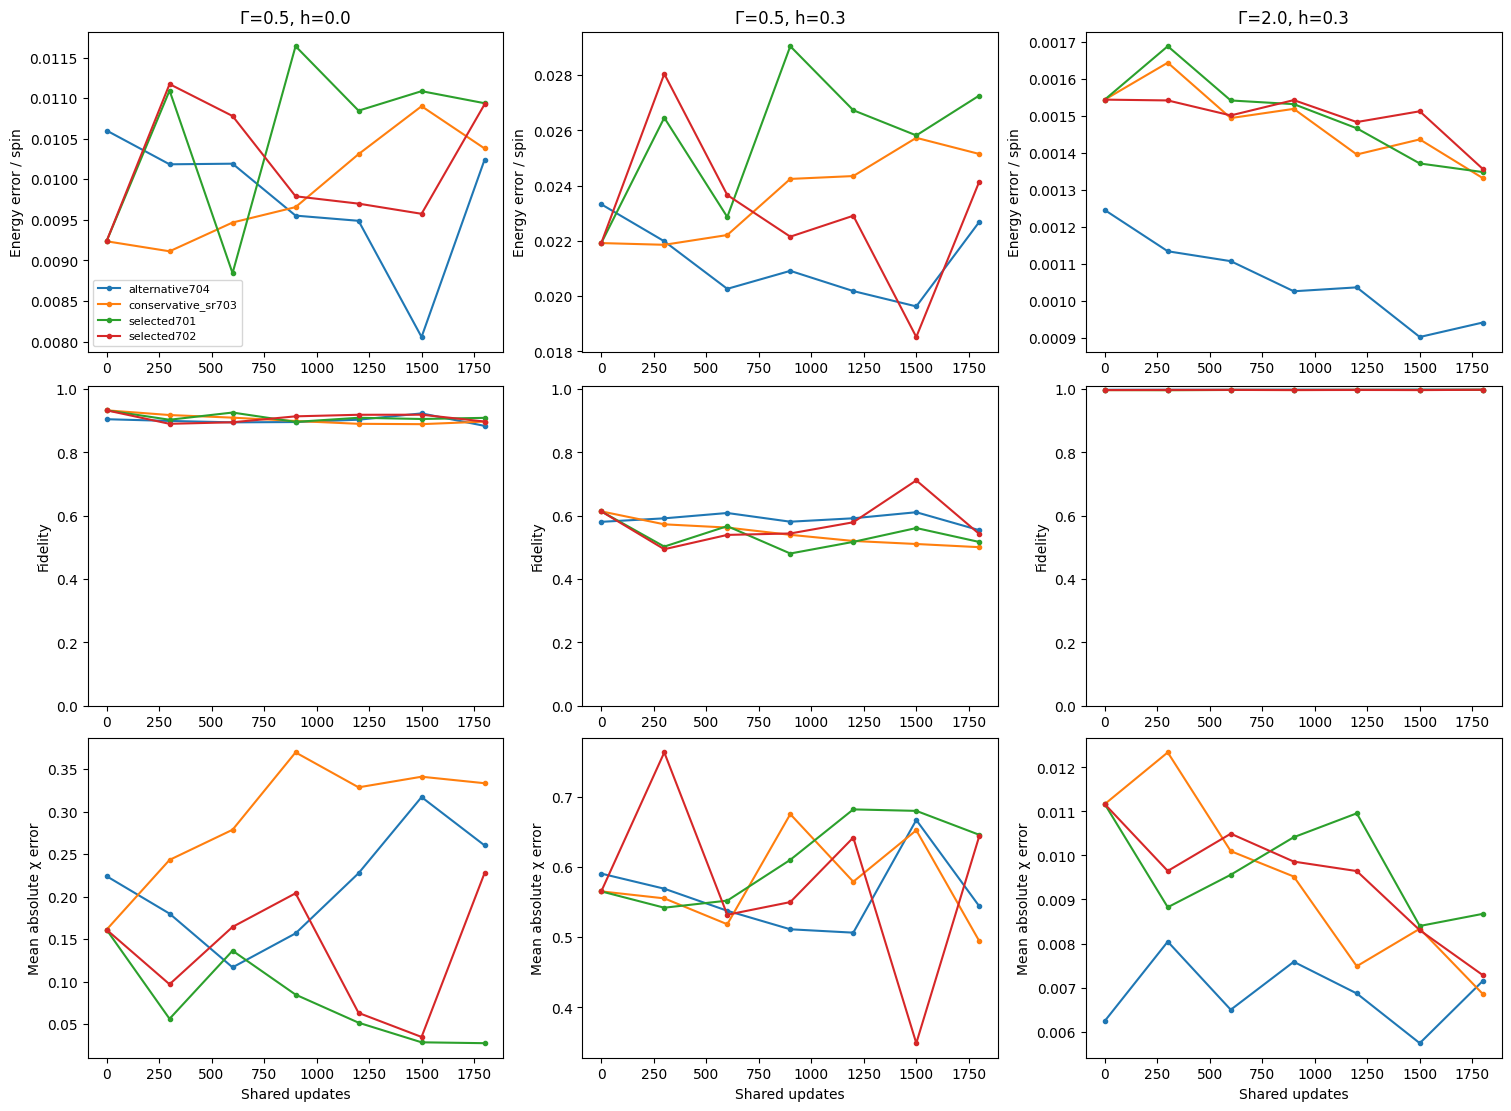

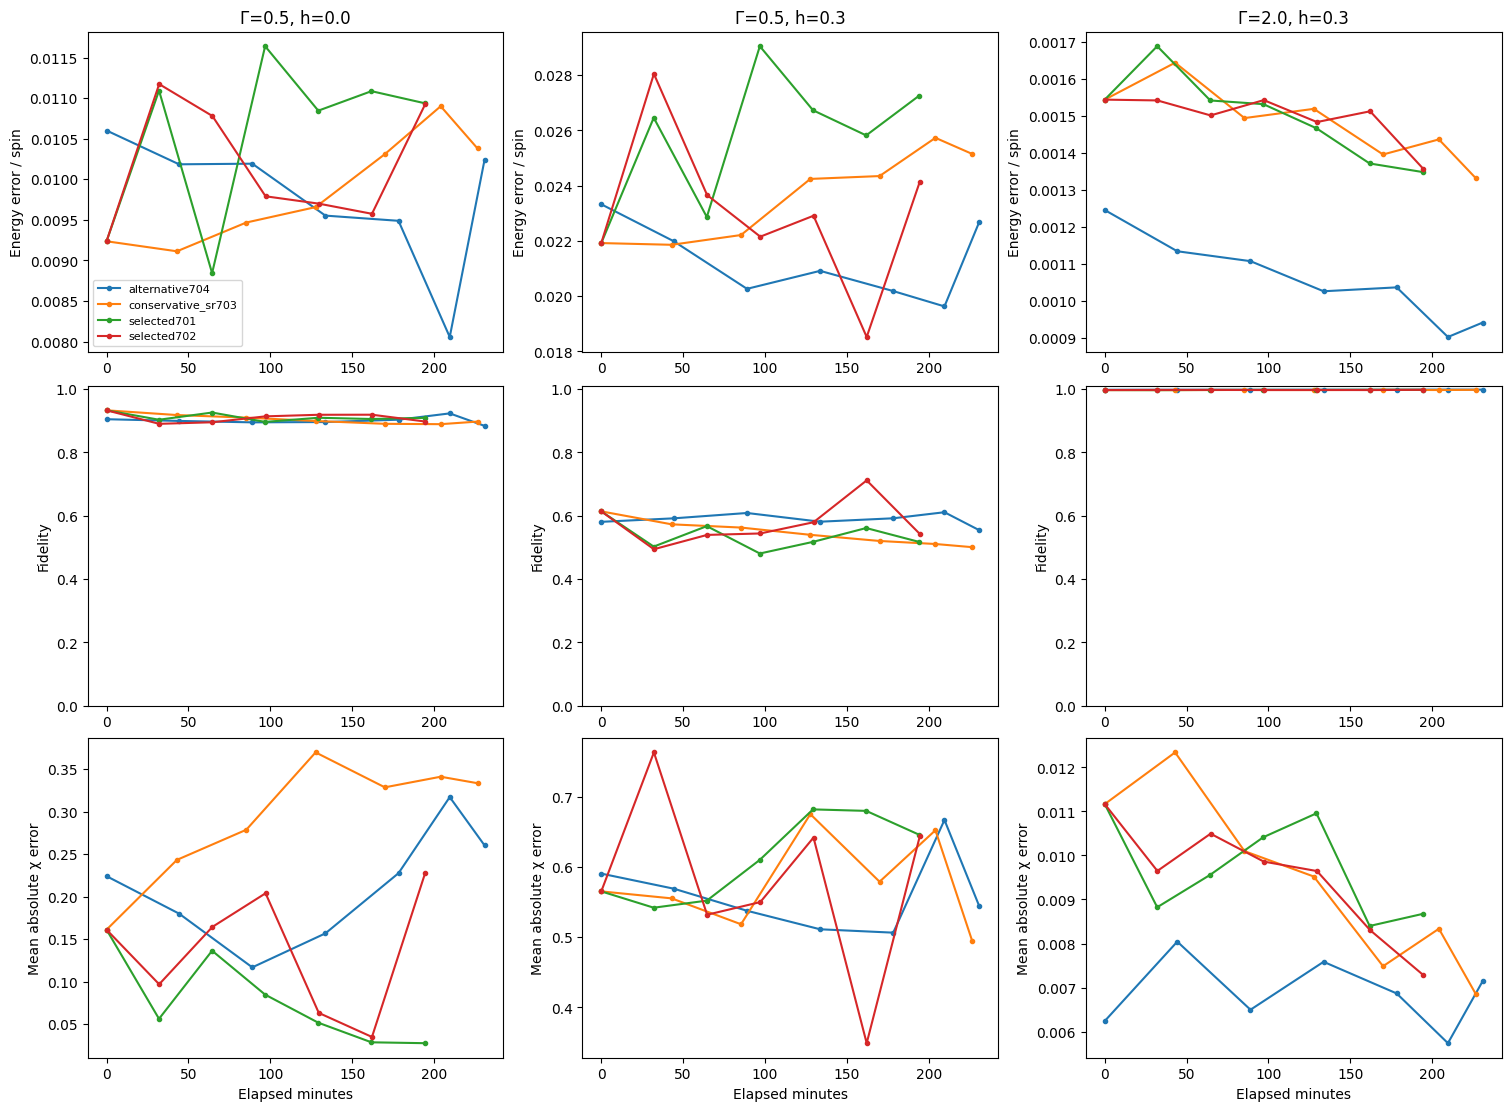

Elapsed time starts after initialization validation and includes preceding in-run validations and resource contention. Curves show measured validation points; no accuracy is inferred between them.

In [4]:
common_steps=set.intersection(*(set(v['step'] for v in r['validations']) for r in runs.values()))
if common_steps:
    matched=max(common_steps)
    table=['| Run | Matched updates | Γ | h | Mean error/spin | Mean fidelity | Change in fidelity | Mean absolute χ error |', '|---|---:|---:|---:|---:|---:|---:|---:|']
    for name,r in runs.items():
        current=next(v for v in r['validations'] if v['step']==matched)
        initial=next(v for v in r['validations'] if v['step']==0)
        for gamma,h in ((.5,0.),(.5,.3),(2.,.3)):
            selected=[v for v in current['rows'] if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
            start=[v for v in initial['rows'] if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
            fidelity=np.mean([v['fidelity'] for v in selected])
            table.append(f"| {name} | {matched} | {gamma} | {h} | {np.mean([v['energy_error_per_spin'] for v in selected]):.6f} | {fidelity:.5f} | {fidelity-np.mean([v['fidelity'] for v in start]):+.5f} | {np.mean([abs(v['chi_connected']-v['exact_chi']) for v in selected]):.5f} |")
    display(Markdown('**Largest validation update shared by every run**\n\n'+'\n'.join(table)))
for horizontal in ('updates','seconds'):
    fig,axes=plt.subplots(3,3,figsize=(15,11),constrained_layout=True)
    for column,(gamma,h) in enumerate(((.5,0.),(.5,.3),(2.,.3))):
        for name,r in runs.items():
            seconds={v['step']:v['seconds'] for v in r['history']}
            seconds[0]=0.
            points=[]
            for validation in r['validations']:
                selected=[v for v in validation['rows'] if v['L']==2 and v['sample_id'] in (10000,10001) and (v['gamma'],v['h'])==(gamma,h)]
                step=validation['step']
                if not selected or (horizontal=='seconds' and step not in seconds): continue
                x=step if horizontal=='updates' else seconds[step]/60
                points.append((x,np.mean([v['energy_error_per_spin'] for v in selected]),np.mean([v['fidelity'] for v in selected]),np.mean([abs(v['chi_connected']-v['exact_chi']) for v in selected])))
            if points:
                p=np.asarray(points)
                for row in range(3): axes[row,column].plot(p[:,0],p[:,row+1],'.-',label=name)
        axes[0,column].set_title(f'Γ={gamma}, h={h}')
        for row,label in enumerate(('Energy error / spin','Fidelity','Mean absolute χ error')):
            axes[row,column].set_ylabel(label)
        axes[2,column].set_xlabel('Shared updates' if horizontal=='updates' else 'Elapsed minutes')
        axes[1,column].set_ylim(0,1.01)
    axes[0,0].legend(fontsize=8)
    fig.savefig(ROOT/f'validation_{horizontal}.png',dpi=180)
    fig.savefig(ROOT/f'validation_{horizontal}.pdf')
    plt.show()
display(Markdown('Elapsed time starts after initialization validation and includes preceding in-run validations and resource contention. Curves show measured validation points; no accuracy is inferred between them.'))


In [5]:
table=['| Run | L | Γ | h | Sampled E/spin ± SE | Connected χ ± SE |', '|---|---:|---:|---:|---:|---:|']
for name,r in runs.items():
    if not r['validations']: continue
    for v in r['validations'][-1]['rows']:
        if v['L']==2: continue
        q=v['sampled']; n=3*v['L']**2
        table.append(f"| {name} | {v['L']} | {v['gamma']} | {v['h']} | {q['energy']['mean']/n:.6f} ± {q['energy']['se']/n:.6f} | {q['chi_connected']['mean']:.5f} ± {q['chi_connected']['se']:.5f} |")
display(Markdown('\n'.join(table)))
display(Markdown('Larger-size values are variational sample estimates; no exact reference or ground-state fidelity is inferred from them. Equal update counts and recorded wall time answer different optimization-efficiency questions.'))


| Run | L | Γ | h | Sampled E/spin ± SE | Connected χ ± SE |
|---|---:|---:|---:|---:|---:|
| alternative704 | 4 | 0.5 | 0.0 | -1.076134 ± 0.000467 | 3.38883 ± 0.06373 |
| alternative704 | 4 | 0.5 | 0.3 | -1.092401 ± 0.000646 | 2.92220 ± 0.29611 |
| alternative704 | 4 | 2.0 | 0.3 | -2.241515 ± 0.000721 | 1.18262 ± 0.04884 |
| alternative704 | 6 | 0.5 | 0.0 | -1.063957 ± 0.000579 | 3.39981 ± 0.19540 |
| alternative704 | 6 | 0.5 | 0.3 | -1.080266 ± 0.002406 | 1.66363 ± 0.09050 |
| alternative704 | 6 | 2.0 | 0.3 | -2.234432 ± 0.000905 | 1.09368 ± 0.08299 |
| alternative704 | 8 | 0.5 | 0.0 | -1.029795 ± 0.001509 | 3.38932 ± 0.25746 |
| alternative704 | 8 | 0.5 | 0.3 | -1.046935 ± 0.000949 | 2.48478 ± 0.26697 |
| alternative704 | 8 | 2.0 | 0.3 | -2.218408 ± 0.000650 | 1.11088 ± 0.03765 |
| conservative_sr703 | 4 | 0.5 | 0.0 | -1.075161 ± 0.001136 | 3.57959 ± 0.21895 |
| conservative_sr703 | 4 | 0.5 | 0.3 | -1.094515 ± 0.003191 | 2.09147 ± 0.12146 |
| conservative_sr703 | 4 | 2.0 | 0.3 | -2.240687 ± 0.000740 | 1.15951 ± 0.06522 |
| conservative_sr703 | 6 | 0.5 | 0.0 | -1.064185 ± 0.000963 | 3.42151 ± 0.24088 |
| conservative_sr703 | 6 | 0.5 | 0.3 | -1.079412 ± 0.001677 | 1.70428 ± 0.07440 |
| conservative_sr703 | 6 | 2.0 | 0.3 | -2.233312 ± 0.000513 | 1.10532 ± 0.10534 |
| conservative_sr703 | 8 | 0.5 | 0.0 | -1.027818 ± 0.001666 | 3.48100 ± 0.24556 |
| conservative_sr703 | 8 | 0.5 | 0.3 | -1.045618 ± 0.000215 | 2.30945 ± 0.17091 |
| conservative_sr703 | 8 | 2.0 | 0.3 | -2.218046 ± 0.000836 | 1.10649 ± 0.03392 |
| selected701 | 4 | 0.5 | 0.0 | -1.072161 ± 0.001273 | 3.72233 ± 0.20440 |
| selected701 | 4 | 0.5 | 0.3 | -1.095659 ± 0.002313 | 1.81901 ± 0.08569 |
| selected701 | 4 | 2.0 | 0.3 | -2.240656 ± 0.000678 | 1.18083 ± 0.07717 |
| selected701 | 6 | 0.5 | 0.0 | -1.059302 ± 0.000414 | 3.44170 ± 0.26675 |
| selected701 | 6 | 0.5 | 0.3 | -1.072525 ± 0.001103 | 1.85988 ± 0.09852 |
| selected701 | 6 | 2.0 | 0.3 | -2.233028 ± 0.000549 | 1.07038 ± 0.09179 |
| selected701 | 8 | 0.5 | 0.0 | -1.025845 ± 0.000970 | 3.89742 ± 0.51740 |
| selected701 | 8 | 0.5 | 0.3 | -1.043228 ± 0.000658 | 2.24288 ± 0.11662 |
| selected701 | 8 | 2.0 | 0.3 | -2.217737 ± 0.000726 | 1.12524 ± 0.04797 |
| selected702 | 4 | 0.5 | 0.0 | -1.072198 ± 0.001990 | 3.88558 ± 0.24487 |
| selected702 | 4 | 0.5 | 0.3 | -1.095331 ± 0.001507 | 1.76969 ± 0.05276 |
| selected702 | 4 | 2.0 | 0.3 | -2.240898 ± 0.000947 | 1.17253 ± 0.05467 |
| selected702 | 6 | 0.5 | 0.0 | -1.057777 ± 0.000556 | 3.56771 ± 0.36425 |
| selected702 | 6 | 0.5 | 0.3 | -1.073667 ± 0.000898 | 1.95320 ± 0.08465 |
| selected702 | 6 | 2.0 | 0.3 | -2.233301 ± 0.000533 | 1.12131 ± 0.09715 |
| selected702 | 8 | 0.5 | 0.0 | -1.024780 ± 0.001523 | 3.85026 ± 0.54009 |
| selected702 | 8 | 0.5 | 0.3 | -1.043310 ± 0.000699 | 2.10978 ± 0.05383 |
| selected702 | 8 | 2.0 | 0.3 | -2.217806 ± 0.000691 | 1.10844 ± 0.06591 |

Larger-size values are variational sample estimates; no exact reference or ground-state fidelity is inferred from them. Equal update counts and recorded wall time answer different optimization-efficiency questions.

In [6]:
spectra=[('initial',ROOT/'initial_low_field_spectrum.json')]
spectra += [(name,path) for name in runs for path in sorted((ROOT/name).glob('low_field_spectrum_*.json'))]
for name,path in spectra:
    if path.exists():
        diagnostic=json.loads(path.read_text())
        checkpoint=Path(diagnostic['checkpoint']) if name=='initial' else ROOT/name/diagnostic['checkpoint']
        assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==diagnostic['sha256']
        table=['| ID | Γ | h | Accessible gap | Fidelity | First excited weight | First 16 weight | ΔE/gap |','|---:|---:|---:|---:|---:|---:|---:|---:|']
        for v in diagnostic['rows']:
            table.append(f"| {v['sample_id']} | {v['gamma']} | {v['h']} | {v['accessible_gap']:.6f} | {v['ground_fidelity']:.5f} | {v['spectral_weights'][1]:.5f} | {v['first_16_weight']:.5f} | {v['energy_excess_over_gap']:.3f} |")
        display(Markdown('**'+name+' — '+path.name+'**\n\n'+'\n'.join(table)))


**alternative704 — low_field_spectrum_final.json**

| ID | Γ | h | Accessible gap | Fidelity | First excited weight | First 16 weight | ΔE/gap |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.94314 | 0.00080 | 0.97597 | 0.456 |
| 10000 | 0.5 | 0.3 | 0.297950 | 0.34801 | 0.47548 | 0.96195 | 1.197 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.99817 | 0.00011 | 0.99886 | 0.006 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.82460 | 0.03343 | 0.98599 | 0.405 |
| 10001 | 0.5 | 0.3 | 0.146645 | 0.76081 | 0.00958 | 0.96910 | 1.283 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.99847 | 0.00010 | 0.99925 | 0.004 |

**conservative_sr703 — low_field_spectrum_final.json**

| ID | Γ | h | Accessible gap | Fidelity | First excited weight | First 16 weight | ΔE/gap |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.93608 | 0.00128 | 0.98023 | 0.453 |
| 10000 | 0.5 | 0.3 | 0.297950 | 0.33318 | 0.50275 | 0.96575 | 1.204 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.99732 | 0.00003 | 0.99800 | 0.009 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.85870 | 0.00701 | 0.98291 | 0.415 |
| 10001 | 0.5 | 0.3 | 0.146645 | 0.66853 | 0.00304 | 0.96386 | 1.670 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.99801 | 0.00035 | 0.99908 | 0.006 |

**selected701 — low_field_spectrum_final.json**

| ID | Γ | h | Accessible gap | Fidelity | First excited weight | First 16 weight | ΔE/gap |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.96395 | 0.00141 | 0.97815 | 0.394 |
| 10000 | 0.5 | 0.3 | 0.297950 | 0.44227 | 0.44569 | 0.96920 | 0.986 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.99729 | 0.00005 | 0.99791 | 0.010 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.85443 | 0.02444 | 0.97227 | 0.491 |
| 10001 | 0.5 | 0.3 | 0.146645 | 0.59232 | 0.01982 | 0.93303 | 2.459 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.99818 | 0.00009 | 0.99903 | 0.006 |

**selected702 — low_field_spectrum_final.json**

| ID | Γ | h | Accessible gap | Fidelity | First excited weight | First 16 weight | ΔE/gap |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 10000 | 0.5 | 0.0 | 0.224844 | 0.95064 | 0.00885 | 0.97727 | 0.417 |
| 10000 | 0.5 | 0.3 | 0.297950 | 0.49340 | 0.43851 | 0.97482 | 0.844 |
| 10000 | 2.0 | 0.3 | 2.098484 | 0.99724 | 0.00003 | 0.99789 | 0.010 |
| 10001 | 0.5 | 0.0 | 0.354349 | 0.84459 | 0.04216 | 0.97535 | 0.476 |
| 10001 | 0.5 | 0.3 | 0.146645 | 0.59148 | 0.03457 | 0.94106 | 2.238 |
| 10001 | 2.0 | 0.3 | 2.218306 | 0.99817 | 0.00004 | 0.99907 | 0.006 |

## Frozen-guide correlations and field response

The following uses full 12-spin enumeration on the two development disorders.
RMS and maximum correlation errors exclude the matrix diagonal. The field scan
uses h=0.15, outside the discrete anchors, and does not adapt the guide.


| Checkpoint | ID | Γ | h | Fidelity | RMS connected-C error | Max connected-C error | Absolute Δχ |
|---|---:|---:|---:|---:|---:|---:|---:|
| selected701 step1800 | 10000 | 0.5 | 0.0 | 0.96395 | 0.05408 | 0.12031 | 0.01441 |
| selected701 step1800 | 10000 | 0.5 | 0.3 | 0.44227 | 0.18321 | 0.54702 | 0.92870 |
| selected701 step1800 | 10000 | 2.0 | 0.3 | 0.99729 | 0.01375 | 0.06100 | 0.01066 |
| selected701 step1800 | 10000 | 0.4 | 0.15 | 0.34686 | 0.17106 | 0.39775 | 0.83466 |
| selected701 step1800 | 10000 | 0.7 | 0.15 | 0.90475 | 0.06100 | 0.19245 | 0.40761 |
| selected701 step1800 | 10000 | 1.0 | 0.15 | 0.97979 | 0.03284 | 0.08568 | 0.01985 |
| selected701 step1800 | 10000 | 1.5 | 0.15 | 0.99332 | 0.02262 | 0.08323 | 0.02822 |
| selected701 step1800 | 10001 | 0.5 | 0.0 | 0.85443 | 0.22218 | 0.51600 | 0.04118 |
| selected701 step1800 | 10001 | 0.5 | 0.3 | 0.59232 | 0.11769 | 0.35074 | 0.36367 |
| selected701 step1800 | 10001 | 2.0 | 0.3 | 0.99818 | 0.00981 | 0.02418 | 0.00669 |
| selected701 step1800 | 10001 | 0.4 | 0.15 | 0.50990 | 0.11414 | 0.23611 | 0.40376 |
| selected701 step1800 | 10001 | 0.7 | 0.15 | 0.91531 | 0.07737 | 0.18434 | 0.24672 |
| selected701 step1800 | 10001 | 1.0 | 0.15 | 0.98124 | 0.03721 | 0.09976 | 0.05286 |
| selected701 step1800 | 10001 | 1.5 | 0.15 | 0.99595 | 0.01659 | 0.03972 | 0.01802 |
| selected702 step1800 | 10000 | 0.5 | 0.0 | 0.95064 | 0.10414 | 0.25876 | 0.19045 |
| selected702 step1800 | 10000 | 0.5 | 0.3 | 0.49340 | 0.17714 | 0.58006 | 0.85767 |
| selected702 step1800 | 10000 | 2.0 | 0.3 | 0.99724 | 0.01376 | 0.06118 | 0.00969 |
| selected702 step1800 | 10000 | 0.4 | 0.15 | 0.34581 | 0.14151 | 0.38405 | 0.66712 |
| selected702 step1800 | 10000 | 0.7 | 0.15 | 0.89981 | 0.06013 | 0.16694 | 0.35842 |
| selected702 step1800 | 10000 | 1.0 | 0.15 | 0.97975 | 0.03249 | 0.07754 | 0.01676 |
| selected702 step1800 | 10000 | 1.5 | 0.15 | 0.99334 | 0.02229 | 0.07817 | 0.02708 |
| selected702 step1800 | 10001 | 0.5 | 0.0 | 0.84459 | 0.24125 | 0.54648 | 0.26496 |
| selected702 step1800 | 10001 | 0.5 | 0.3 | 0.59148 | 0.11983 | 0.33170 | 0.43131 |
| selected702 step1800 | 10001 | 2.0 | 0.3 | 0.99817 | 0.00933 | 0.02477 | 0.00488 |
| selected702 step1800 | 10001 | 0.4 | 0.15 | 0.51472 | 0.12014 | 0.27120 | 0.46194 |
| selected702 step1800 | 10001 | 0.7 | 0.15 | 0.90646 | 0.07959 | 0.19310 | 0.31386 |
| selected702 step1800 | 10001 | 1.0 | 0.15 | 0.98206 | 0.03490 | 0.09433 | 0.04759 |
| selected702 step1800 | 10001 | 1.5 | 0.15 | 0.99612 | 0.01548 | 0.03845 | 0.01455 |
| conservative_sr703 step1800 | 10000 | 0.5 | 0.0 | 0.93608 | 0.10296 | 0.25839 | 0.23377 |
| conservative_sr703 step1800 | 10000 | 0.5 | 0.3 | 0.33318 | 0.17800 | 0.42947 | 0.90757 |
| conservative_sr703 step1800 | 10000 | 2.0 | 0.3 | 0.99732 | 0.01361 | 0.05344 | 0.01002 |
| conservative_sr703 step1800 | 10000 | 0.4 | 0.15 | 0.26629 | 0.16708 | 0.40620 | 0.81698 |
| conservative_sr703 step1800 | 10000 | 0.7 | 0.15 | 0.87058 | 0.06754 | 0.20014 | 0.33591 |
| conservative_sr703 step1800 | 10000 | 1.0 | 0.15 | 0.97581 | 0.04126 | 0.11119 | 0.02254 |
| conservative_sr703 step1800 | 10000 | 1.5 | 0.15 | 0.99408 | 0.02199 | 0.07332 | 0.02390 |
| conservative_sr703 step1800 | 10001 | 0.5 | 0.0 | 0.85870 | 0.20658 | 0.49354 | 0.43276 |
| conservative_sr703 step1800 | 10001 | 0.5 | 0.3 | 0.66853 | 0.10558 | 0.31210 | 0.08145 |
| conservative_sr703 step1800 | 10001 | 2.0 | 0.3 | 0.99801 | 0.01003 | 0.02471 | 0.00369 |
| conservative_sr703 step1800 | 10001 | 0.4 | 0.15 | 0.58119 | 0.07649 | 0.19520 | 0.02425 |
| conservative_sr703 step1800 | 10001 | 0.7 | 0.15 | 0.88223 | 0.10162 | 0.27175 | 0.34187 |
| conservative_sr703 step1800 | 10001 | 1.0 | 0.15 | 0.97161 | 0.04654 | 0.11568 | 0.05498 |
| conservative_sr703 step1800 | 10001 | 1.5 | 0.15 | 0.99551 | 0.01766 | 0.04020 | 0.00848 |
| alternative704 step1800 | 10000 | 0.5 | 0.0 | 0.94314 | 0.08872 | 0.29065 | 0.28956 |
| alternative704 step1800 | 10000 | 0.5 | 0.3 | 0.34801 | 0.18957 | 0.44890 | 0.99743 |
| alternative704 step1800 | 10000 | 2.0 | 0.3 | 0.99817 | 0.00991 | 0.02624 | 0.00807 |
| alternative704 step1800 | 10000 | 0.4 | 0.15 | 0.28425 | 0.18533 | 0.43368 | 0.95970 |
| alternative704 step1800 | 10000 | 0.7 | 0.15 | 0.86653 | 0.05945 | 0.21014 | 0.36109 |
| alternative704 step1800 | 10000 | 1.0 | 0.15 | 0.97718 | 0.02999 | 0.08258 | 0.00529 |
| alternative704 step1800 | 10000 | 1.5 | 0.15 | 0.99514 | 0.01728 | 0.05022 | 0.01795 |
| alternative704 step1800 | 10001 | 0.5 | 0.0 | 0.82460 | 0.23915 | 0.62796 | 0.23083 |
| alternative704 step1800 | 10001 | 0.5 | 0.3 | 0.76081 | 0.09383 | 0.27984 | 0.09106 |
| alternative704 step1800 | 10001 | 2.0 | 0.3 | 0.99847 | 0.00996 | 0.02333 | 0.00623 |
| alternative704 step1800 | 10001 | 0.4 | 0.15 | 0.56912 | 0.10895 | 0.21146 | 0.17107 |
| alternative704 step1800 | 10001 | 0.7 | 0.15 | 0.89799 | 0.09983 | 0.23310 | 0.39619 |
| alternative704 step1800 | 10001 | 1.0 | 0.15 | 0.97845 | 0.04027 | 0.10705 | 0.06861 |
| alternative704 step1800 | 10001 | 1.5 | 0.15 | 0.99555 | 0.01757 | 0.04217 | 0.01619 |

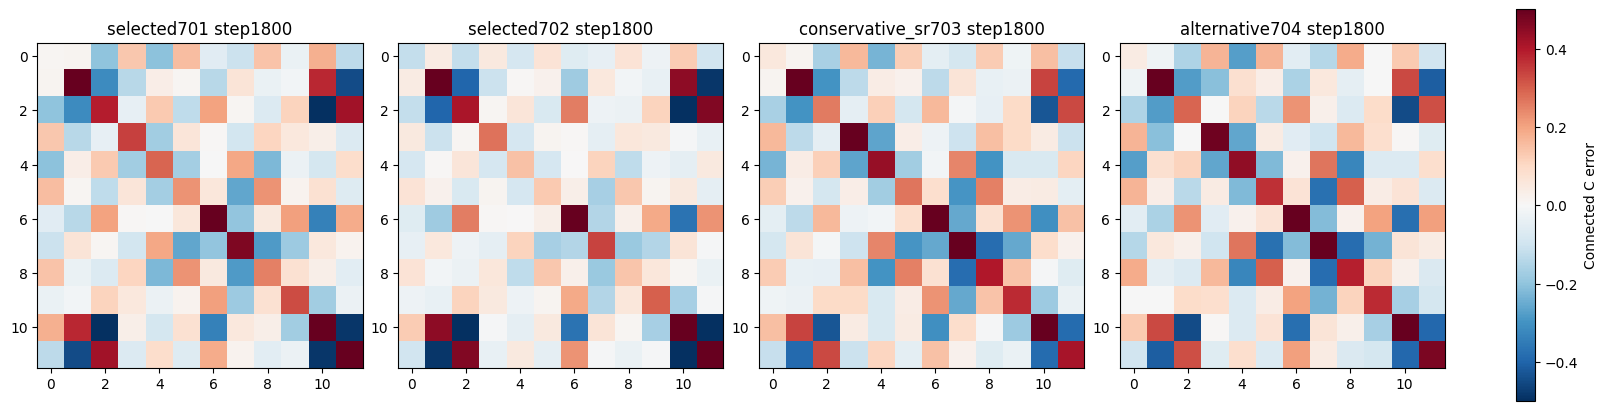

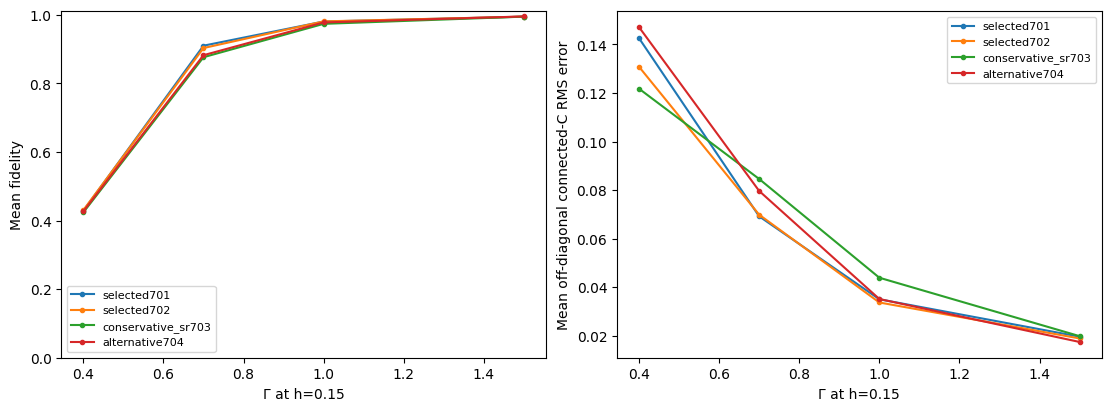

In [7]:
comparisons=[]
for filename in ('initial_correlation_comparison.json','correlation_comparison.json'):
    path=ROOT/filename
    if path.exists():
        diagnostic=json.loads(path.read_text())
        for run in diagnostic['runs']:
            checkpoint=Path(run['checkpoint'])
            assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==run['sha256']
            comparisons.append(dict(run,label='initial' if filename.startswith('initial') else checkpoint.parent.name))
if comparisons:
    table=['| Checkpoint | ID | Γ | h | Fidelity | RMS connected-C error | Max connected-C error | Absolute Δχ |', '|---|---:|---:|---:|---:|---:|---:|---:|']
    for run in comparisons:
        for v in run['rows']:
            table.append(f"| {run['label']} step{run['step']} | {v['sample_id']} | {v['gamma']} | {v['h']} | {v['fidelity']:.5f} | {v['connected_correlation_rms_error']:.5f} | {v['connected_correlation_max_error']:.5f} | {abs(v['chi_connected']-v['exact_chi']):.5f} |")
    display(Markdown('\n'.join(table)))
    # The lowest-field biased context exposes competing patterns directly.
    selected=[(run,[v for v in run['rows'] if (v['sample_id'],v['gamma'],v['h'])==(10000,.5,.3)]) for run in comparisons]
    selected=[(run,rows[0]) for run,rows in selected if rows]
    if selected:
        fig,axes=plt.subplots(1,len(selected),figsize=(4*len(selected),4),squeeze=False,constrained_layout=True)
        for ax,(run,v) in zip(axes[0],selected):
            error=np.asarray(v['connected_correlation'])-np.asarray(v['exact_connected_correlation'])
            image=ax.imshow(error,cmap='RdBu_r',vmin=-.5,vmax=.5)
            ax.set_title(run['label']+f" step{run['step']}")
        fig.colorbar(image,ax=list(axes[0]),label='Connected C error')
        fig.savefig(ROOT/'connected_correlation_errors.png',dpi=180)
        fig.savefig(ROOT/'connected_correlation_errors.pdf')
        plt.show()
    fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    for run in comparisons:
        gammas=sorted({v['gamma'] for v in run['rows'] if v['h']==.15})
        if not gammas: continue
        selected=[[v for v in run['rows'] if (v['gamma'],v['h'])==(gamma,.15)] for gamma in gammas]
        axes[0].plot(gammas,[np.mean([v['fidelity'] for v in group]) for group in selected],'.-',label=run['label'])
        axes[1].plot(gammas,[np.mean([v['connected_correlation_rms_error'] for v in group]) for group in selected],'.-',label=run['label'])
    axes[0].set(ylabel='Mean fidelity',ylim=(0,1.01))
    axes[1].set_ylabel('Mean off-diagonal connected-C RMS error')
    for ax in axes:
        ax.set_xlabel('Γ at h=0.15')
        if ax.lines: ax.legend(fontsize=8)
    fig.savefig(ROOT/'field_response.png',dpi=180)
    fig.savefig(ROOT/'field_response.pdf')
    plt.show()


## Exact imaginary-time projection reference

Each curve applies normalized exp[−τ(H−E₀)]ψ to all 4096 configurations. It
measures how long the frozen guide takes to approach the exact finite-size
ground state. It provides a target for stochastic projection, whose walker
population, branching interval, and forward-time errors still need convergence
studies. These curves establish no accuracy for systems larger than 12 spins.


| Guide | ID | Γ | h | Initial F | Final τ | Final F | Final C RMS error | First grid τ with F≥0.99 | First grid τ with F≥0.999 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| alternative704 | 10000 | 0.5 | 0.0 | 0.943143 | 16.0 | 0.99999936 | 0.000647647 | 1.0 | 4.0 |
| alternative704 | 10000 | 0.5 | 0.3 | 0.348012 | 16.0 | 0.99990117 | 0.00298979 | 16.0 | 16.0 |
| alternative704 | 10000 | 2.0 | 0.3 | 0.998166 | 16.0 | 1.00000000 | 6.36123e-15 | 0.0 | 0.5 |
| alternative704 | 10001 | 0.5 | 0.0 | 0.824598 | 16.0 | 0.99999949 | 0.000522733 | 4.0 | 8.0 |
| alternative704 | 10001 | 0.5 | 0.3 | 0.760805 | 16.0 | 0.99987469 | 0.00431697 | 8.0 | 16.0 |
| alternative704 | 10001 | 2.0 | 0.3 | 0.998470 | 16.0 | 1.00000000 | 3.2792e-15 | 0.0 | 0.5 |
| conservative_sr703 | 10000 | 0.5 | 0.0 | 0.936079 | 16.0 | 0.99999897 | 0.000823269 | 1.0 | 4.0 |
| conservative_sr703 | 10000 | 0.5 | 0.3 | 0.333178 | 16.0 | 0.99989085 | 0.00314579 | 16.0 | 16.0 |
| conservative_sr703 | 10000 | 2.0 | 0.3 | 0.997317 | 16.0 | 1.00000000 | 6.36002e-15 | 0.0 | 0.5 |
| conservative_sr703 | 10001 | 0.5 | 0.0 | 0.858703 | 16.0 | 0.99999988 | 0.000247325 | 4.0 | 8.0 |
| conservative_sr703 | 10001 | 0.5 | 0.3 | 0.668534 | 16.0 | 0.99988922 | 0.00189977 | 8.0 | 16.0 |
| conservative_sr703 | 10001 | 2.0 | 0.3 | 0.998007 | 16.0 | 1.00000000 | 3.28816e-15 | 0.0 | 0.5 |
| selected701 | 10000 | 0.5 | 0.0 | 0.963955 | 16.0 | 0.99999890 | 0.00085005 | 0.5 | 2.0 |
| selected701 | 10000 | 0.5 | 0.3 | 0.442271 | 16.0 | 0.99992711 | 0.00255923 | 8.0 | 16.0 |
| selected701 | 10000 | 2.0 | 0.3 | 0.997291 | 16.0 | 1.00000000 | 6.36195e-15 | 0.0 | 0.5 |
| selected701 | 10001 | 0.5 | 0.0 | 0.854426 | 16.0 | 0.99999965 | 0.000434148 | 4.0 | 8.0 |
| selected701 | 10001 | 0.5 | 0.3 | 0.592317 | 16.0 | 0.99963252 | 0.00632365 | 8.0 | 16.0 |
| selected701 | 10001 | 2.0 | 0.3 | 0.998182 | 16.0 | 1.00000000 | 3.283e-15 | 0.0 | 0.5 |
| selected702 | 10000 | 0.5 | 0.0 | 0.950640 | 16.0 | 0.99999302 | 0.00214509 | 2.0 | 8.0 |
| selected702 | 10000 | 0.5 | 0.3 | 0.493401 | 16.0 | 0.99993572 | 0.00240062 | 8.0 | 16.0 |
| selected702 | 10000 | 2.0 | 0.3 | 0.997239 | 16.0 | 1.00000000 | 6.36312e-15 | 0.0 | 0.5 |
| selected702 | 10001 | 0.5 | 0.0 | 0.844585 | 16.0 | 0.99999939 | 0.000568807 | 4.0 | 8.0 |
| selected702 | 10001 | 0.5 | 0.3 | 0.591484 | 16.0 | 0.99939409 | 0.00866466 | 8.0 | 16.0 |
| selected702 | 10001 | 2.0 | 0.3 | 0.998170 | 16.0 | 1.00000000 | 3.28305e-15 | 0.0 | 0.5 |

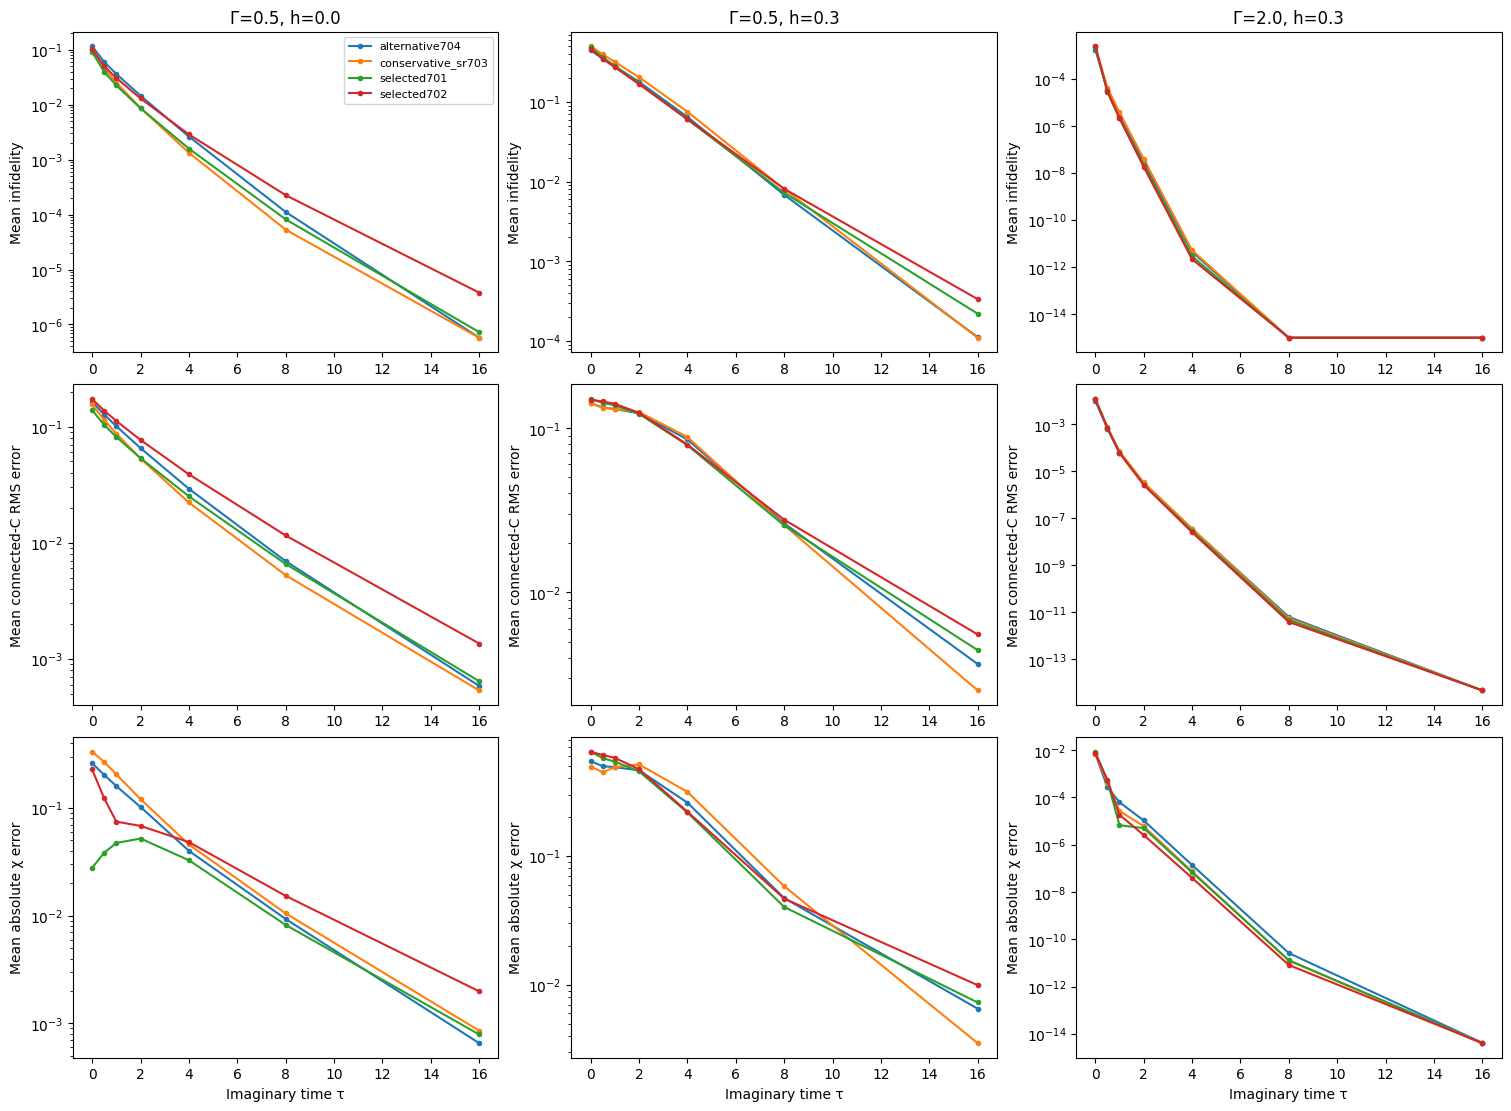

In [8]:
projections=[]
paths=[ROOT/'initial_exact_projection.json']+sorted(ROOT.glob('*/exact_projection_final.json'))
for path in paths:
    if not path.exists(): continue
    diagnostic=json.loads(path.read_text())
    assert hashlib.sha256(Path(diagnostic['checkpoint']).read_bytes()).hexdigest()==diagnostic['sha256']
    projections.append(dict(diagnostic,label='initial' if path.name.startswith('initial') else path.parent.name))
if projections:
    table=['| Guide | ID | Γ | h | Initial F | Final τ | Final F | Final C RMS error | First grid τ with F≥0.99 | First grid τ with F≥0.999 |','|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|']
    for run in projections:
        for v in run['rows']:
            trajectory=v['trajectory']; first,last=trajectory[0],trajectory[-1]
            reached=[next((str(q['tau']) for q in trajectory if q['fidelity']>=threshold),'not reached') for threshold in (.99,.999)]
            table.append(f"| {run['label']} | {v['sample_id']} | {v['gamma']} | {v['h']} | {first['fidelity']:.6f} | {last['tau']} | {last['fidelity']:.8f} | {last['connected_correlation_rms_error']:.6g} | {reached[0]} | {reached[1]} |")
    display(Markdown('\n'.join(table)))
    fig,axes=plt.subplots(3,3,figsize=(15,11),constrained_layout=True)
    for column,(gamma,h) in enumerate(((.5,0.),(.5,.3),(2.,.3))):
        for run in projections:
            selected=[v['trajectory'] for v in run['rows'] if (v['gamma'],v['h'])==(gamma,h)]
            times=[q['tau'] for q in selected[0]]
            means=np.mean([[[max(0.,1-q['fidelity']),q['connected_correlation_rms_error'],abs(q['chi_connected']-q['exact_chi'])] for q in trajectory] for trajectory in selected],axis=0)
            for row in range(3): axes[row,column].semilogy(times,np.maximum(means[:,row],1e-15),'.-',label=run['label'])
        axes[0,column].set_title(f'Γ={gamma}, h={h}')
        for row,label in enumerate(('Mean infidelity','Mean connected-C RMS error','Mean absolute χ error')): axes[row,column].set_ylabel(label)
        axes[2,column].set_xlabel('Imaginary time τ')
    axes[0,0].legend(fontsize=8)
    fig.savefig(ROOT/'exact_projection.png',dpi=180)
    fig.savefig(ROOT/'exact_projection.pdf')
    plt.show()


## Stochastic projector convergence study

The frozen network is cached exactly on all 12-spin configurations for this
CPU study. Independent four-replica walker populations estimate connected
susceptibility. Error bars are across independent populations; every forward
cycle is included regardless of ancestry quality. A small ancestry ESS flags
unreliable forward walking and is not a reason to discard a result.


In [9]:
for path in sorted(ROOT.glob('projector_*/summary.json')):
    study=json.loads(path.read_text())
    base_settings=len(study['manifest']['walkers'])*len(study['manifest']['forward'])
    extra_cadence=max(0, len(study['manifest']['blocks'])-1)
    expected=len(study['manifest']['ids'])*2*(base_settings+extra_cadence)*study['manifest']['seeds']
    available=len(list(path.parent.glob('s*_seed*.json')))
    display(Markdown(f"**{path.parent.name}** — completed: {study['completed']}; summarized settings: {len(study['rows'])}; independent population records: {available}/{expected}."))
    if not study['completed']:
        display(Markdown('Partial snapshot: the resumable study is still running; missing settings are not interpreted as zero or omitted data.'))
    table=['| ID | h | Walkers | Forward τ | Branch Δτ | χ ± population SE | Exact χ | E error/spin ± SE | Min ancestry ESS | Largest lineage |','|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|']
    for v in study['rows']:
        c=v['observables']['chi_connected']; e=v['observables']['energy']
        table.append(f"| {v['sample_id']} | {v['h']} | {v['walkers']} | {v['tau_forward']} | {v['tau_block']} | {c['mean']:.5f} ± {c['se']:.5f} | {c['exact']:.5f} | {e['bias']/12:.6f} ± {e['se']/12:.6f} | {v['min_descendant_ess']:.2f} | {v['max_largest_lineage']:.3f} |")
    display(Markdown('\n'.join(table)))
    focus=[v for v in study['rows'] if v['walkers']==max(study['manifest']['walkers']) and v['tau_forward']==max(study['manifest']['forward'])]
    if focus:
        table=['| ID | h | Branch Δτ | χ estimate ± population SE | Exact χ | Difference / SE | Min descendant ESS | Largest lineage | Healthy populations |','|---:|---:|---:|---:|---:|---:|---:|---:|---:|']
        for v in focus:
            q=v['observables']['chi_connected']; z=(q['mean']-q['exact'])/q['se']
            table.append(f"| {v['sample_id']} | {v['h']} | {v['tau_block']} | {q['mean']:.5f} ± {q['se']:.5f} | {q['exact']:.5f} | {z:+.2f} | {v['min_descendant_ess']:.1f} | {v['max_largest_lineage']:.3f} | {v['healthy_populations']}/{v['independent_populations']} |")
        display(Markdown('**Longest forward-time check at the largest population**\n\n'+ '\n'.join(table)))
    if (10000,.3) in {(v['sample_id'],v['h']) for v in study['rows']}:
        population=[v for v in study['rows'] if (v['sample_id'],v['h'],v['tau_forward'],v['tau_block'])==(10000,.3,max(study['manifest']['forward'],key=float),study['manifest']['blocks'][0])]
        if population:
            table=['| Walkers | χ estimate ± population SE | Exact χ | Min descendant ESS | Largest lineage |','|---:|---:|---:|---:|---:|']
            for v in sorted(population,key=lambda x:x['walkers']):
                q=v['observables']['chi_connected']
                table.append(f"| {v['walkers']} | {q['mean']:.5f} ± {q['se']:.5f} | {q['exact']:.5f} | {v['min_descendant_ess']:.1f} | {v['max_largest_lineage']:.3f} |")
            display(Markdown('**Population dependence at ID10000, h=0.3, longest forward time**\n\n'+'\n'.join(table)))
        display(Markdown('At these 12-spin settings, the projected energy estimates can be close to the exact energy while connected susceptibility remains sensitive to disorder, forward time, walker population and branching cadence. Ancestry diagnostics and independent-population errors are reported together; agreement of energy alone does not establish observable convergence.'))
    fig,axes=plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
    for ax,(sample_id,h) in zip(axes.flat,((10000,0.),(10000,.3),(10001,0.),(10001,.3))):
        rows=[v for v in study['rows'] if (v['sample_id'],v['h'])==(sample_id,h)]
        for block in sorted({v['tau_block'] for v in rows}):
            for walkers in sorted({v['walkers'] for v in rows}):
                selected=sorted([v for v in rows if (v['walkers'],v['tau_block'])==(walkers,block)],key=lambda v:v['tau_forward'])
                if not selected: continue
                ax.errorbar([v['tau_forward'] for v in selected],[v['observables']['chi_connected']['mean'] for v in selected],yerr=[v['observables']['chi_connected']['se'] for v in selected],fmt='.-',label=f'W={walkers}, Δτ={block}')
        if rows: ax.axhline(rows[0]['observables']['chi_connected']['exact'],color='black',ls='--',label='Exact')
        ax.set(title=f'ID{sample_id}, h={h}',xlabel='Forward time',ylabel='Connected χ')
        if ax.lines: ax.legend(fontsize=7)
    fig.savefig(path.parent/'convergence.png',dpi=180)
    fig.savefig(path.parent/'convergence.pdf')
    plt.show()


These are controlled optimization experiments, not a qualification for finite-size scaling. A useful remedy must improve unseen-disorder observables and fidelity consistently, retain its high-field accuracy, and survive independent seeds. The reserved disorders should be inspected only after choosing the continuation from development results.